In [2]:
import sqlite3
import pandas  as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
conn = sqlite3.connect('inventory.db')

In [4]:
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)
for table in tables['name']:
    print(f'Table name: {table}')
    display(pd.read_sql_query(f"SELECT * FROM {table} LIMIT 5", conn))

Table name: purchases


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1


Table name: purchase_prices


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


Table name: vendor_invoice


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


Table name: begin_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


Table name: end_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


In [5]:
purchase_agg_df = pd.read_sql_query('''
select
p.PONumber,
count(distinct p.Brand) as total_brands,
sum(p.Quantity) as total_item_quantity,
sum(p.Dollars) as total_item_dollars,
avg(julianday (p.receivingDate) - julianday(p.PODate)) as avg_receiving_delay
from purchases p
group by p.PONumber        
''', conn)

In [6]:
pd.read_sql_query('''
select
vi.Quantity as invoice_quantity,
vi.Dollars as invoice_dollars,
vi.Freight,
(julianday(vi.InvoiceDate)-julianday(vi.PODate)) as days_po_to_invoice,
(julianday(vi.PayDate)-julianday(vi.InvoiceDate)) as days_to_pay
from vendor_invoice vi''', conn)

,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay
0,6,214.26,3.47,14.0,43.0
1,15,140.55,8.57,16.0,45.0
2,5,106.60,4.61,16.0,38.0
3,10100,137483.78,2935.20,23.0,24.0
4,1935,15527.25,429.20,14.0,36.0
...,...,...,...,...,...
5538,90,1563.00,8.60,16.0,35.0
5539,4617,37300.48,186.50,18.0,39.0
5540,9848,202815.78,932.95,11.0,33.0
5541,24747,149007.56,819.54,14.0,36.0


In [7]:
df= pd.read_sql_query('''
WITH purchase_agg AS (                  
    select
    p.PONumber,
    count(distinct p.Brand) as total_brands,
    sum(p.Quantity) as total_item_quantity,
    sum(p.Dollars) as total_item_dollars,
    avg(julianday (p.receivingDate) - julianday(p.PODate)) as avg_receiving_delay
    from purchases p
    group by p.PONumber                  
)                      
select
    vi.Quantity as invoice_quantity,
    vi.Dollars as invoice_dollars,
    vi.Freight,
    (julianday(vi.InvoiceDate)-julianday(vi.PODate)) as days_po_to_invoice,
    (julianday(vi.PayDate)-julianday(vi.InvoiceDate)) as days_to_pay,
    pa.total_brands,
    pa.total_item_quantity,
    pa.total_item_dollars,
    pa.avg_receiving_delay
from vendor_invoice vi
left join purchase_agg pa on vi.PONumber = pa.PONumber                                 
''', conn)

In [75]:
df.isnull().sum()

invoice_quantity       0
invoice_dollars        0
Freight                0
days_po_to_invoice     0
days_to_pay            0
total_brands           0
total_item_quantity    0
total_item_dollars     0
avg_receiving_delay    0
dtype: int64

In [76]:
def create_invoice_risk_label(row):

    #Invoice total mismatch with item-level total
    if (abs(row['invoice_dollars'] - row['total_item_dollars']) > 5):
        return 1
    
    #Abnoramlly high receiving delay
    if (row['avg_receiving_delay'] > 10):
        return 1
    
    return 0
df['flag_invoice'] = df.apply(create_invoice_risk_label, axis=1)
df['flag_invoice'].value_counts()


flag_invoice
0    3693
1    1850
Name: count, dtype: int64

<Axes: title={'center': 'Invoice Risk Flag Distribution'}, xlabel='flag_invoice'>

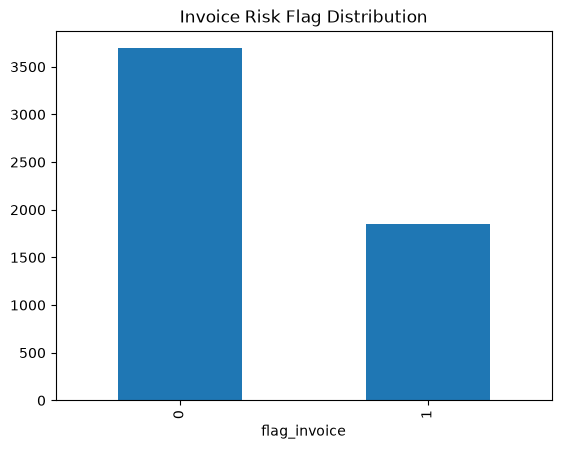

In [77]:
df['flag_invoice'].value_counts().plot(kind='bar', title='Invoice Risk Flag Distribution')

In [78]:
df.corr()

,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay,flag_invoice
invoice_quantity,1.000000,0.963831,0.946550,0.000526,0.022284,0.566394,0.706117,0.668171,0.000519,0.032783
invoice_dollars,0.963831,1.000000,0.985141,0.001610,0.025661,0.536952,0.667666,0.679537,0.004694,0.037994
Freight,0.946550,0.985141,1.000000,0.003265,0.025513,0.536381,0.656616,0.670768,0.015645,0.037759
days_po_to_invoice,0.000526,0.001610,0.003265,1.000000,-0.370432,0.009519,0.005543,0.007931,0.515538,0.183115
days_to_pay,0.022284,0.025661,0.025513,-0.370432,1.000000,0.020336,0.016203,0.015610,-0.029403,-0.005289
total_brands,0.566394,0.536952,0.536381,0.009519,0.020336,1.000000,0.783825,0.753092,0.000496,0.008961
total_item_quantity,0.706117,0.667666,0.656616,0.005543,0.016203,0.783825,1.000000,0.963831,-0.014016,0.032783
total_item_dollars,0.668171,0.679537,0.670768,0.007931,0.015610,0.753092,0.963831,1.000000,-0.014251,0.037994
avg_receiving_delay,0.000519,0.004694,0.015645,0.515538,-0.029403,0.000496,-0.014016,-0.014251,1.000000,0.311667
flag_invoice,0.032783,0.037994,0.037759,0.183115,-0.005289,0.008961,0.032783,0.037994,0.311667,1.000000


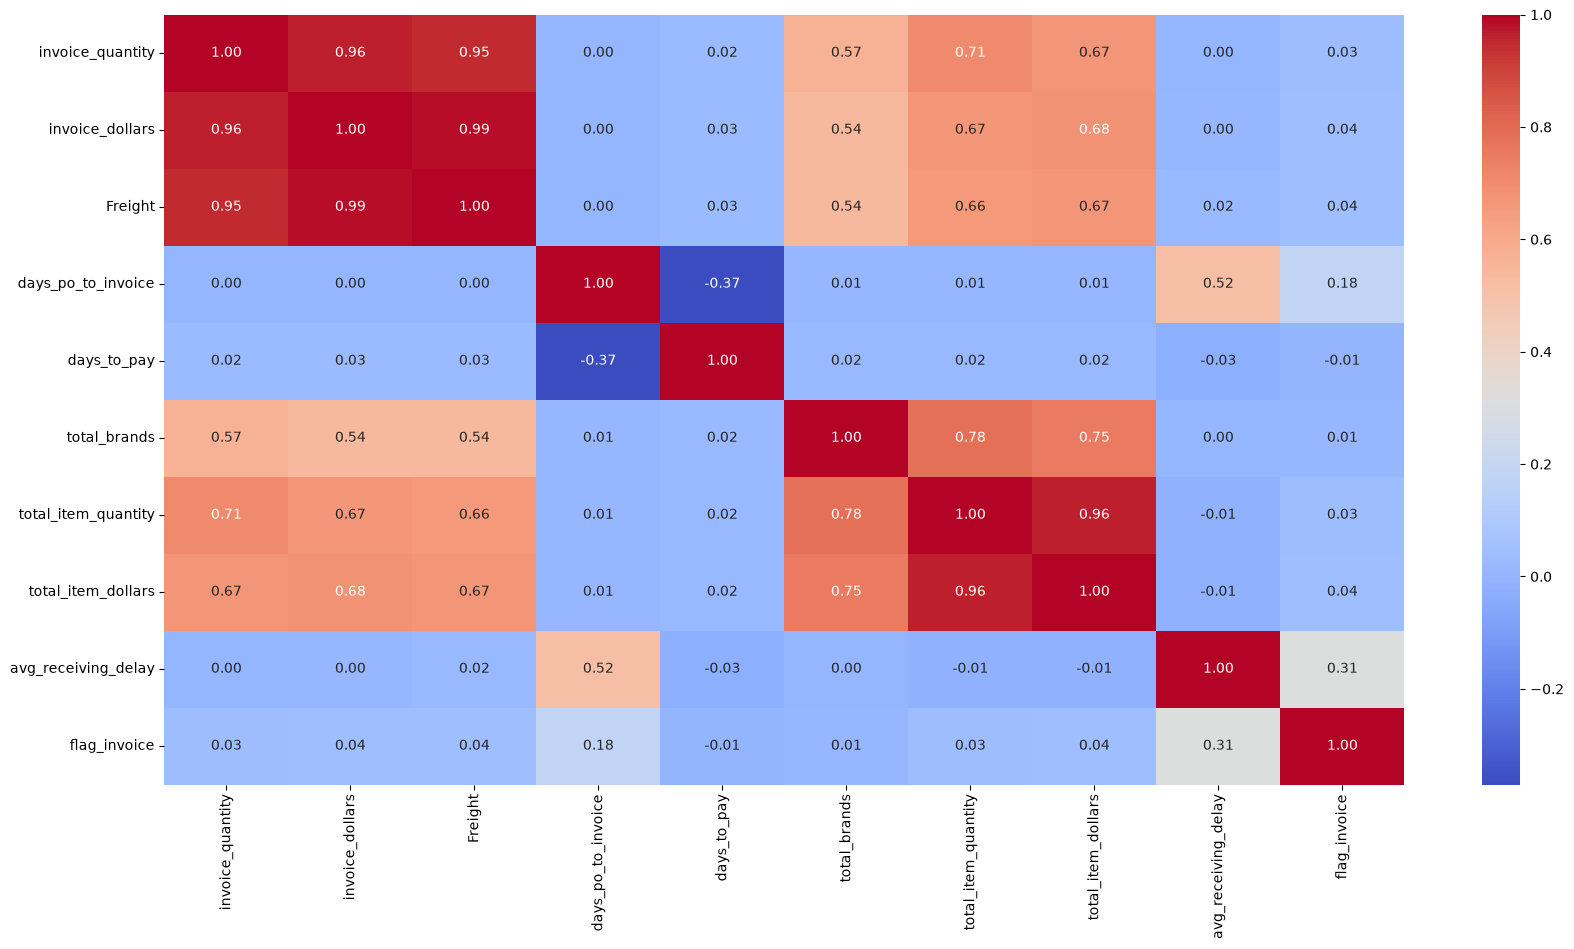

In [79]:
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [80]:
flagged = df[df['flag_invoice'] == 1]
normal = df[df['flag_invoice'] == 0]

In [81]:
significant_features = []
non_significant_features = []
results = []

In [82]:
metrics = ['invoice_quantity', 'invoice_dollars', 'Freight', 'days_po_to_invoice', 'days_to_pay', 'total_brands', 'total_item_quantity', 'total_item_dollars', 'avg_receiving_delay']

In [83]:
from scipy.stats import ttest_ind
for metric in metrics:
    flagged_mean = flagged[metric].mean()
    normal_mean = normal[metric].mean()

    t_stat,p_value = ttest_ind(
        flagged[metric].dropna(),
        normal[metric].dropna(),
        equal_var = False
    )

    if p_value < 0.05:
        significant_features.append(metric)
        results.append({
            'metrics':metric,
            'flagged_mean' : flagged_mean.round(2),
            'normal_mean': normal_mean.round(2),
            'p_value':p_value.round(3)
        })

    else:
        non_significant_features.append(metric)
        print(metric)
        print({
            'metric':metric,
            'flagged_mean':flagged_mean.round(2),
            'normal_mean':normal_mean.round(2),
            'p_value':p_value.round(3)
        })


days_to_pay
{'metric': 'days_to_pay', 'flagged_mean': np.float64(35.42), 'normal_mean': np.float64(35.49), 'p_value': np.float64(0.692)}
total_brands
{'metric': 'total_brands', 'flagged_mean': np.float64(42.29), 'normal_mean': np.float64(40.82), 'p_value': np.float64(0.508)}


In [84]:
non_significant_features

['days_to_pay', 'total_brands']

In [85]:
significant_features

['invoice_quantity',
 'invoice_dollars',
 'Freight',
 'days_po_to_invoice',
 'total_item_quantity',
 'total_item_dollars',
 'avg_receiving_delay']

In [86]:
results

[{'metrics': 'invoice_quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(5723.55),
  'p_value': np.float64(0.021)},
 {'metrics': 'invoice_dollars',
  'flagged_mean': np.float64(65600.61),
  'normal_mean': np.float64(54302.64),
  'p_value': np.float64(0.008)},
 {'metrics': 'Freight',
  'flagged_mean': np.float64(334.02),
  'normal_mean': np.float64(276.89),
  'p_value': np.float64(0.008)},
 {'metrics': 'days_po_to_invoice',
  'flagged_mean': np.float64(17.23),
  'normal_mean': np.float64(16.02),
  'p_value': np.float64(0.0)},
 {'metrics': 'total_item_quantity',
  'flagged_mean': np.float64(6728.28),
  'normal_mean': np.float64(5723.55),
  'p_value': np.float64(0.021)},
 {'metrics': 'total_item_dollars',
  'flagged_mean': np.float64(65600.61),
  'normal_mean': np.float64(54302.64),
  'p_value': np.float64(0.008)},
 {'metrics': 'avg_receiving_delay',
  'flagged_mean': np.float64(8.47),
  'normal_mean': np.float64(7.27),
  'p_value': np.float64(0.0)}]

In [87]:
x = df[['invoice_quantity','invoice_dollars','Freight','total_brands','total_item_quantity','days_po_to_invoice','total_item_dollars']]
y = df['flag_invoice']

In [88]:
x.describe().round()

,invoice_quantity,invoice_dollars,Freight,total_brands,total_item_quantity,days_po_to_invoice,total_item_dollars
count,5543.0,5543.0,5543.0,5543.0,5543.0,5543.0,5543.0
mean,6059.0,58073.0,296.0,41.0,6059.0,16.0,58073.0
std,14453.0,140234.0,714.0,77.0,14453.0,3.0,140234.0
min,1.0,4.0,0.0,1.0,1.0,9.0,4.0
25%,83.0,968.0,5.0,3.0,83.0,14.0,968.0
50%,423.0,4765.0,25.0,7.0,423.0,16.0,4765.0
75%,5100.0,44587.0,230.0,46.0,5100.0,19.0,44587.0
max,141660.0,1660436.0,8468.0,807.0,141660.0,23.0,1660436.0


In [89]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.model_selection import train_test_split
scaler = StandardScaler()
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [90]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

In [91]:
model1 = LogisticRegression(random_state=42)
model1.fit(X_train_scaled , y_train)

model2 = DecisionTreeClassifier(random_state=42)
model2.fit(X_train_scaled , y_train)

model3 = RandomForestClassifier(random_state=42)
model3.fit(X_train_scaled,y_train)

RandomForestClassifier(random_state=42)

In [92]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

models = [
    ('Logistic Regression', model1),
    ('Decision Tree', model2),
    ('Random Forest', model3)
]

for name, model in models:
    y_pred = model.predict(X_test_scaled)
    print(name)
    print('Accuracy:', accuracy_score(y_test, y_pred))
    print('Precision:', precision_score(y_test, y_pred, zero_division=0))
    print('Recall:', recall_score(y_test, y_pred, zero_division=0))
    print('F1 score:', f1_score(y_test, y_pred, zero_division=0))
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
        print('ROC AUC:', roc_auc_score(y_test, y_prob))
    print('Classification report:')
    print(classification_report(y_test, y_pred, zero_division=0))
    print('Confusion matrix:')
    print(confusion_matrix(y_test, y_pred))
    print('-' * 40)

Logistic Regression
Accuracy: 0.6717763751127142
Precision: 0.5789473684210527
Recall: 0.05945945945945946
F1 score: 0.10784313725490197
ROC AUC: 0.5999341696229383
Classification report:
              precision    recall  f1-score   support

           0       0.68      0.98      0.80       739
           1       0.58      0.06      0.11       370

    accuracy                           0.67      1109
   macro avg       0.63      0.52      0.45      1109
weighted avg       0.64      0.67      0.57      1109

Confusion matrix:
[[723  16]
 [348  22]]
----------------------------------------
Decision Tree
Accuracy: 0.8187556357078449
Precision: 0.7353760445682451
Recall: 0.7135135135135136
F1 score: 0.7242798353909465
ROC AUC: 0.7924807080422778
Classification report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.87       739
           1       0.74      0.71      0.72       370

    accuracy                           0.82      1109
   ma

In [93]:
model3.feature_importances_

array([0.14247549, 0.15605337, 0.14531062, 0.08294927, 0.17626282,
       0.07634923, 0.2205992 ])

In [94]:
feature_importance = pd.DataFrame({
    'feature' : X_train.columns,
    'importance' : model3.feature_importances_
    }).sort_values(by='importance',ascending=False)

feature_importance

,feature,importance
6,total_item_dollars,0.220599
4,total_item_quantity,0.176263
1,invoice_dollars,0.156053
2,Freight,0.145311
0,invoice_quantity,0.142475
3,total_brands,0.082949
5,days_po_to_invoice,0.076349


In [95]:
x = df[['invoice_quantity','invoice_dollars','Freight','total_item_quantity','total_item_dollars']]
y = df['flag_invoice']

In [96]:
X_train , X_test ,y_train ,y_test =train_test_split(x,y,test_size=0.2,random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [97]:

model3 = RandomForestClassifier(random_state=42)
model3.fit(X_train_scaled,y_train)

RandomForestClassifier(random_state=42)

In [98]:

y_pred = model3.predict(X_test_scaled)
print('RandomForestClassifier')
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, zero_division=0))
print('Recall:', recall_score(y_test, y_pred, zero_division=0))
print('F1 score:', f1_score(y_test, y_pred, zero_division=0))
if hasattr(model3, 'predict_proba'):
    y_prob = model3.predict_proba(X_test_scaled)[:, 1]
    print('ROC AUC:', roc_auc_score(y_test, y_prob))
print('Classification report:')
print(classification_report(y_test, y_pred, zero_division=0))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print('-' * 40)

RandomForestClassifier
Accuracy: 0.8845807033363391
Precision: 0.935374149659864
Recall: 0.7161458333333334
F1 score: 0.8112094395280236
ROC AUC: 0.8664098419540229
Classification report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92       725
           1       0.94      0.72      0.81       384

    accuracy                           0.88      1109
   macro avg       0.90      0.84      0.86      1109
weighted avg       0.89      0.88      0.88      1109

Confusion matrix:
[[706  19]
 [109 275]]
----------------------------------------


In [99]:
param_grid = {
    'n_estimators' : [100,200,300],
    'max_depth':[None,4,5,6],
    'min_samples_split':[2,3,5],
    'criterion':['gini','entropy']
}

In [100]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators' : [100,200,300],
    'max_depth':[None,4,5,6],
    'min_samples_split':[2,3,5],
    'criterion':['gini','entropy']
}

scorer = make_scorer(f1_score)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring=scorer,
    cv = 5,
    verbose=2,
    n_jobs=1
)

grid_search.fit(X_train_scaled,y_train)


Fitting 5 folds for each of 72 candidates, totalling 360 fits
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.1s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=200; total time=   0.3s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=200; total time=   0.3s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=200; total time=   0.3s
[CV] END criterion=gini, max_depth=None, min_samples_split=2, n_estimators=200; total time=   0.3s
[CV] END criterion=gini, max_depth=None, min_sa

GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 4, 5, 6],
                         'min_samples_split': [2, 3, 5],
                         'n_estimators': [100, 200, 300]},
             scoring=make_scorer(f1_score, response_method='predict'),
             verbose=2)

Grid Search Best Parameters:
{'criterion': 'gini', 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300}

Best Cross-Validation F1 Score:
0.8006786851917032

Best Model Performance on Test Set:
Accuracy: 0.8899909828674482
Precision: 0.958041958041958
Recall: 0.7135416666666666
F1 Score: 0.817910447761194
ROC AUC: 0.8718660201149425

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.98      0.92       725
           1       0.96      0.71      0.82       384

    accuracy                           0.89      1109
   macro avg       0.91      0.85      0.87      1109
weighted avg       0.90      0.89      0.89      1109


Confusion Matrix:
[[713  12]
 [110 274]]

Feature Importance:
               feature  importance
4   total_item_dollars    0.292142
3  total_item_quantity    0.205262
1      invoice_dollars    0.181134
0     invoice_quantity    0.163378
2              Freight    0.158083


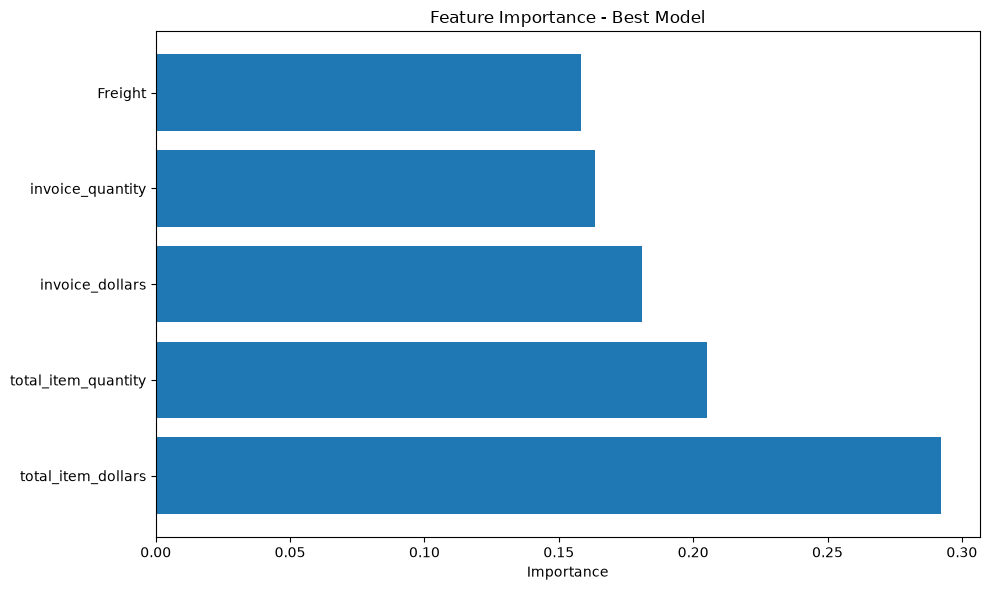

In [101]:
# Evaluate GridSearchCV results and display best parameters and performance
print("Grid Search Best Parameters:")
print(grid_search.best_params_)
print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

# Get the best model
best_model = grid_search.best_estimator_

# Make predictions on test set
y_pred_best = best_model.predict(X_test_scaled)
y_prob_best = best_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate best model
print("\n" + "="*50)
print("Best Model Performance on Test Set:")
print("="*50)
print('Accuracy:', accuracy_score(y_test, y_pred_best))
print('Precision:', precision_score(y_test, y_pred_best, zero_division=0))
print('Recall:', recall_score(y_test, y_pred_best, zero_division=0))
print('F1 Score:', f1_score(y_test, y_pred_best, zero_division=0))
print('ROC AUC:', roc_auc_score(y_test, y_prob_best))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

# Feature importance from best model
feature_importance_best = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values(by='importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance_best)

# Visualize feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_best['feature'], feature_importance_best['importance'])
plt.xlabel('Importance')
plt.title('Feature Importance - Best Model')
plt.tight_layout()
plt.show()

In [102]:
from sklearn.metrics import confusion_matrix

In [104]:
confusion_matrix(grid_search.predict(X_test_scaled),y_test)

array([[713, 110],
       [ 12, 274]])

In [105]:
confusion_matrix(model3.predict(X_test_scaled),y_test)

array([[706, 109],
       [ 19, 275]])

In [106]:
grid_search.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_split': 5,
 'n_estimators': 300}